# Homework 6
## 1. Choropleth map
(a) Suppose we are interested in seeing what the pandemic years did to the perception of public
corruption. Compute the change in CPI from 2019 to 2021 and from 2021 to 2023 or 2025.

In [5]:
import pandas as pd

corruption = pd.read_csv("corruption.csv")
corruption = corruption.rename(columns={"Corruption Perceptions Index": "CPI"})
corruption["CPI"] = pd.to_numeric(corruption["CPI"], errors="coerce")

# One row per country, one column per year
wide = corruption.pivot_table(index=["Entity", "Code"], columns="Year", values="CPI")

# Use 2025 if available, otherwise fall back to 2023
later = wide[2025].fillna(wide[2023]) if 2025 in wide.columns else wide[2023]

changes = pd.DataFrame({
    "change_2019_2021": wide[2021] - wide[2019],
    "change_2021_later": later - wide[2021],
    "pct_change_2019_2021": (wide[2021] - wide[2019]) / wide[2019] * 100,
    "pct_change_2021_later": (later - wide[2021]) / wide[2021] * 100,
}).reset_index()

changes.head()
changes.to_csv("corruption_changes.csv", index=False)

(b) Using the calculated differences, create a choropleth map showing the change for every country/territory. Make sure to use a meaningful color scheme.
![World Corruption](world_corruption.png)

(c) Zoom in on Southeast Asia and change the Coordinate Reference System (CRS) of your map to
a projection suitable for the region.
![Southeast Asia Corruption](SA_corruption.png)

## 2. US CBP Data

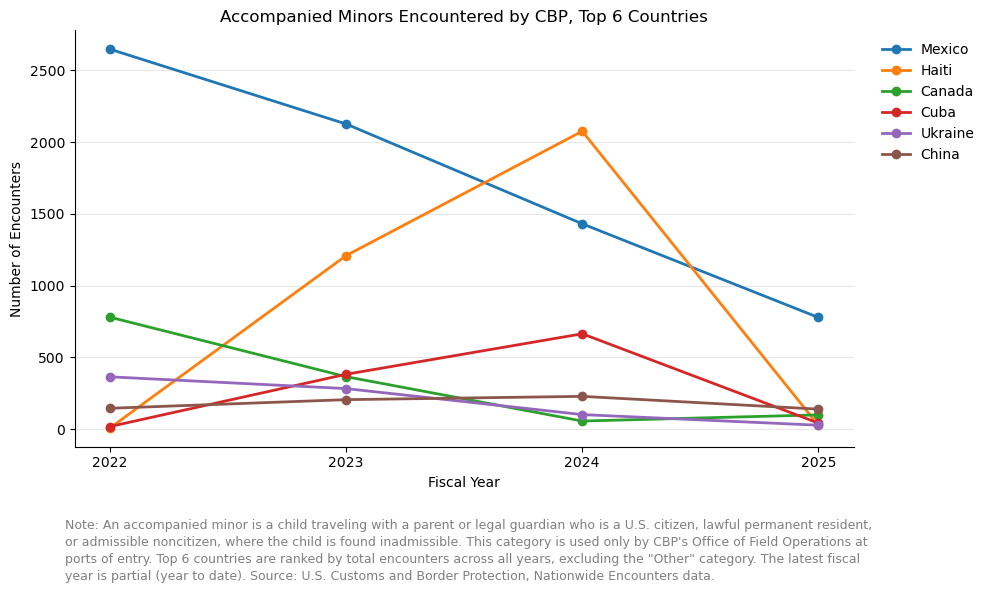

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import textwrap

raw = pd.read_csv("encounters_aor.csv")

# 1. Keep only the demographic you want
minors = raw[raw["Demographic"] == "Accompanied Minors"].copy()   # or "UC / Single Minors"
minors["Citizenship"] = minors["Citizenship"].replace({"CHINA, PEOPLES REPUBLIC OF": "CHINA"})

# 2. Make years integers (handles "2025 (FYTD)")
minors["Fiscal Year"] = minors["Fiscal Year"].astype(str).str[:4].astype(int)

# 3. One total per country per year
minors_grouped = (minors.groupby(["Citizenship", "Fiscal Year"])["Encounter Count"]
                  .sum().reset_index())

# Keep the top 6 countries by total encounters (excluding the catch-all "OTHER")
totals = (minors_grouped[minors_grouped["Citizenship"] != "OTHER"]
          .groupby("Citizenship")["Encounter Count"].sum())
top = totals.nlargest(6).index

fig, ax = plt.subplots(figsize=(10, 6))
for country in top:
    d = minors_grouped[minors_grouped["Citizenship"] == country].sort_values("Fiscal Year")
    ax.plot(d["Fiscal Year"], d["Encounter Count"], marker="o", linewidth=2,
            label=country.title())

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Fiscal Year")
ax.set_ylabel("Number of Encounters")
ax.set_title("Accompanied Minors Encountered by CBP, Top 6 Countries")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

caption = (
    "Note: An accompanied minor is a child traveling with a parent or legal guardian who is a "
    "U.S. citizen, lawful permanent resident, or admissible noncitizen, where the child is found "
    "inadmissible. This category is used only by CBP's Office of Field Operations at ports of entry. "
    "Top 6 countries are ranked by total encounters across all years, excluding the "
    "\"Other\" category. The latest fiscal year is partial (year to date). "
    "Source: U.S. Customs and Border Protection, Nationwide Encounters data."
)

fig.text(0.07, 0.02, textwrap.fill(caption, width=130, replace_whitespace=False),
         ha="left", va="bottom", fontsize=9, color="gray", linespacing=1.4)

plt.tight_layout(rect=[0, 0.15, 1, 1]) # reserve bottom 12% for the caption
plt.show()

In [10]:
# Top citizenship in each area of responsibility (AOR)
aor = (minors[minors["Citizenship"] != "OTHER"]
       .groupby(["AOR (Abbv)", "Citizenship"])["Encounter Count"]
       .sum().reset_index())
aor = aor.sort_values(["AOR (Abbv)", "Encounter Count"], ascending=[True, False])
top_aor = aor.groupby("AOR (Abbv)").head(1).reset_index(drop=True)
top_aor = top_aor.rename(columns={"Encounter Count": "Total Encounters"})
top_aor.to_csv("top_citizenship_by_aor.csv", index=False)
top_aor

,AOR (Abbv),Citizenship,Total Encounters
0,Atlanta,UKRAINE,27
1,Baltimore,UKRAINE,25
2,Boston,CANADA,116
3,Buffalo,CANADA,970
4,Chicago,UKRAINE,131
5,Detroit,CANADA,88
6,El Paso,MEXICO,717
7,Houston,NICARAGUA,95
8,Laredo,MEXICO,3452
9,Los Angeles,NICARAGUA,45


![Accompanied Minors Choropleth](AMC.png)

## AI Statement
I used Claude. For the corruption perceptions maps, Claude helped me debug my pandas code and reshape the data with pivot_table. It also gave feedback on my Datawrapper maps, helping to write titles, descriptions, legend labels, and alt text. For part (c), Claude helped me create a custom Southeast Asia GeoJSON with geopandas so I could change the projection. For the CBP problem, Claude helped fix a KeyError and clean up my line chart, correct geocoding errors on my symbol map, and format the figure caption.